In [1]:
import os, sys, tempfile, subprocess
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions

utilities.set_plot_style()
%matplotlib inline

In [2]:
channels = ["base_ljDisplacementIso",
            'base_ljDisplacementIsohighPtID'
           ]

In [3]:
output_2mu = {}
output_4mu = {}
for channel_name in channels:
    
    output_signal_2mu = functions.load_output("signal_2mu", channel_name)
    output_signal_4mu = functions.load_output("signal_4mu", channel_name)
    output_2mu[channel_name] = output_signal_2mu
    output_4mu[channel_name] = output_signal_4mu

In [4]:
yaml_file_path = '../../configs/ntuples/signal_2mu2e_v10.yaml'
# Open and read the YAML file
with open(yaml_file_path, 'r') as file:
    data = yaml.safe_load(file)
signals_all = list(data["llpNanoAOD_v2"]["samples"].keys())
masses = [500]
signals_2mu = [
    signal for signal in signals_all
    if any(f'{mass}GeV_' in signal for mass in masses)
]

yaml_file_path = '../../configs/ntuples/signal_4mu_v10.yaml'
# Open and read the YAML file
with open(yaml_file_path, 'r') as file:
    data = yaml.safe_load(file)
signals_all = list(data["llpNanoAOD_v2"]["samples"].keys())
masses = [500]
signals_4mu = [
    signal for signal in signals_all
    if any(f'{mass}GeV_' in signal for mass in masses)
]

print(signals_2mu)
print(signals_4mu)

['2Mu2E_500GeV_0p25GeV_0p004mm', '2Mu2E_500GeV_0p25GeV_0p04mm', '2Mu2E_500GeV_0p25GeV_0p4mm', '2Mu2E_500GeV_0p25GeV_2p0mm', '2Mu2E_500GeV_0p25GeV_4p0mm', '2Mu2E_500GeV_1p2GeV_0p019mm', '2Mu2E_500GeV_1p2GeV_0p19mm', '2Mu2E_500GeV_1p2GeV_1p9mm', '2Mu2E_500GeV_1p2GeV_9p6mm', '2Mu2E_500GeV_1p2GeV_19p0mm', '2Mu2E_500GeV_5p0GeV_0p08mm', '2Mu2E_500GeV_5p0GeV_0p8mm', '2Mu2E_500GeV_5p0GeV_8p0mm', '2Mu2E_500GeV_5p0GeV_40p0mm', '2Mu2E_500GeV_5p0GeV_80p0mm']
['4Mu_500GeV_0p25GeV_0p004mm', '4Mu_500GeV_0p25GeV_0p04mm', '4Mu_500GeV_0p25GeV_0p4mm', '4Mu_500GeV_0p25GeV_2p0mm', '4Mu_500GeV_0p25GeV_4p0mm', '4Mu_500GeV_1p2GeV_0p019mm', '4Mu_500GeV_1p2GeV_0p19mm', '4Mu_500GeV_1p2GeV_1p9mm', '4Mu_500GeV_1p2GeV_9p6mm', '4Mu_500GeV_1p2GeV_19p0mm', '4Mu_500GeV_5p0GeV_0p08mm', '4Mu_500GeV_5p0GeV_0p8mm', '4Mu_500GeV_5p0GeV_8p0mm', '4Mu_500GeV_5p0GeV_40p0mm', '4Mu_500GeV_5p0GeV_80p0mm']


In [5]:
histogram_name = "mu_lj_pfMu_max_trkNumPixelHits"

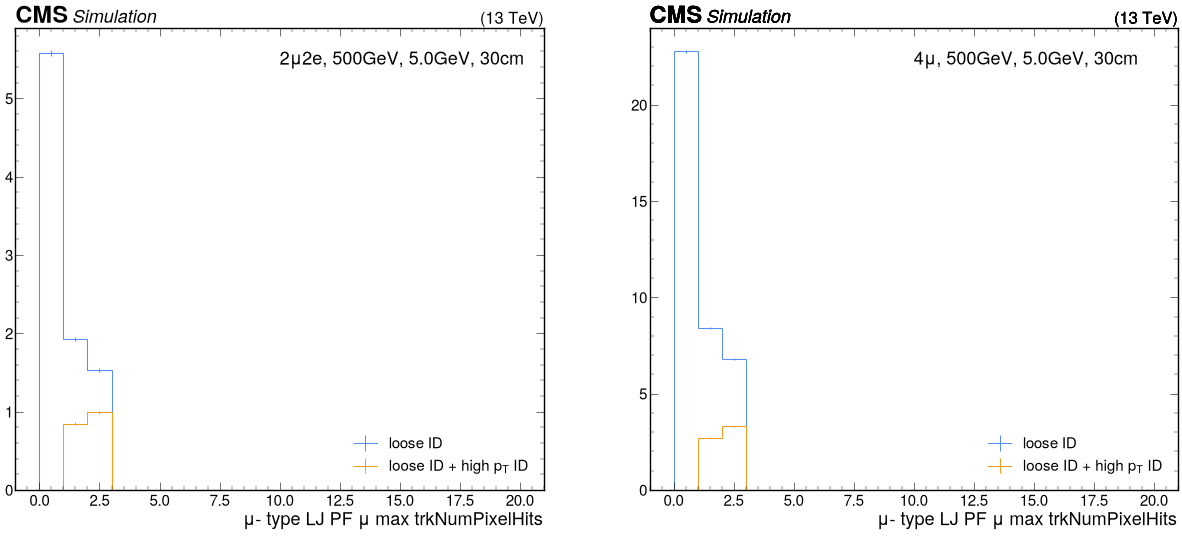

In [7]:
import mplhep as hep
fig, axs = plt.subplots(1, 2, figsize=(15 * 2, 12))
ax = axs[0]
s1 = "2Mu2E_500GeV_5p0GeV_8p0mm"
s2 = "4Mu_500GeV_5p0GeV_8p0mm"

l1 = functions.get_signal_label(s1)
l2 = functions.get_signal_label(s2)

histogram = output_2mu[channels[0]]["out"][s1]["hists"][histogram_name][channels[0], :]
utilities.plot(histogram, ax=ax, label = r"loose ID")
histogram = output_2mu[channels[1]]["out"][s1]["hists"][histogram_name][channels[1], :]
utilities.plot(histogram, ax=ax, label = r"loose ID + high $p_T$ ID")
ax.text(0.5, 0.95, l1,
    transform=ax.transAxes,
    verticalalignment="top"
)
hep.cms.label(ax=ax)
ax = axs[1]
histogram = output_4mu[channels[0]]["out"][s2]["hists"][histogram_name][channels[0], :]
utilities.plot(histogram, ax=ax, label = r"loose ID")
histogram = output_4mu[channels[1]]["out"][s2]["hists"][histogram_name][channels[1], :]
utilities.plot(histogram, ax=ax, label =r"loose ID + high $p_T$ ID")
ax.text(0.5, 0.95, l2,
    transform=ax.transAxes,
    verticalalignment="top"
)
for i in range(2):
    axs[i].legend()

plt.show()


